<a href="https://colab.research.google.com/github/brenoprato/calculo-numerico/blob/main/atividades/atc_interpolacao_erros/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Breno Porto Pinheiro do Prado | 185196

Guilherme Bento Ramos | 185226

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

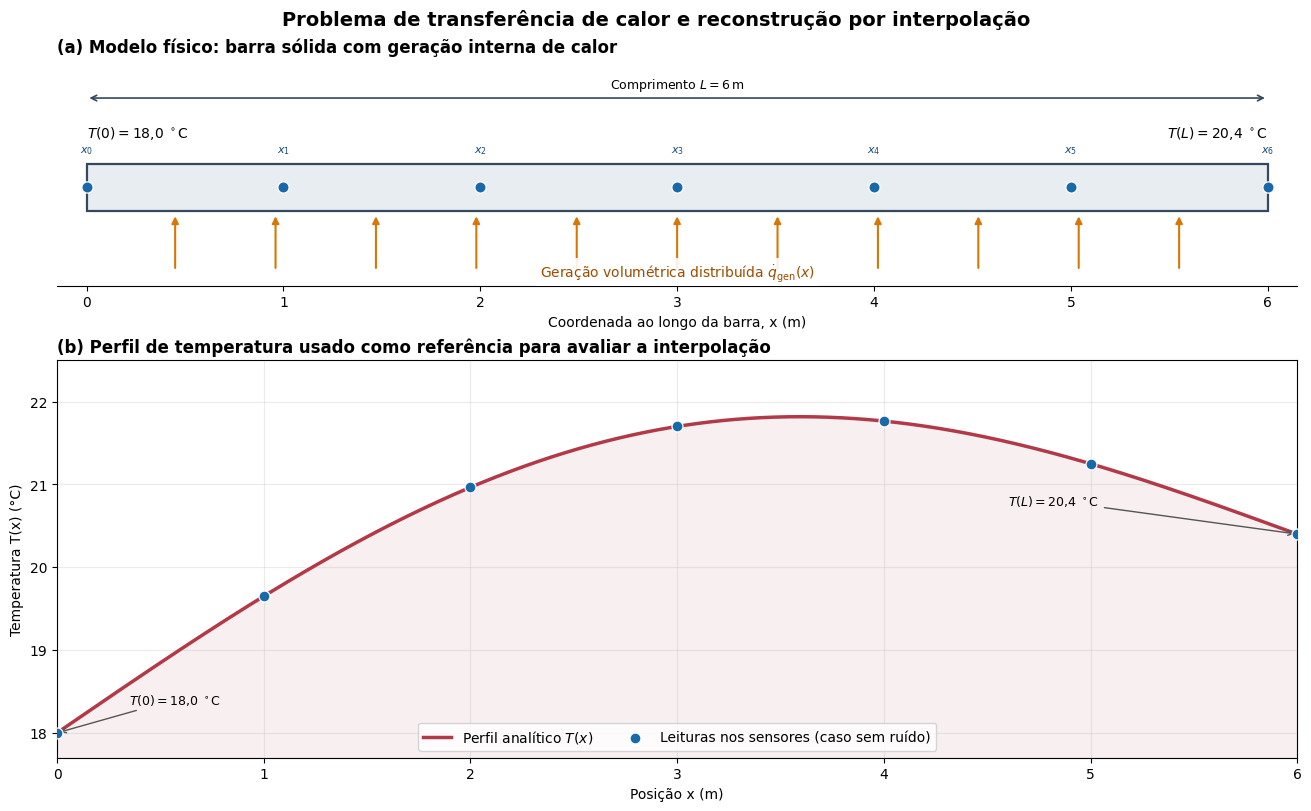

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


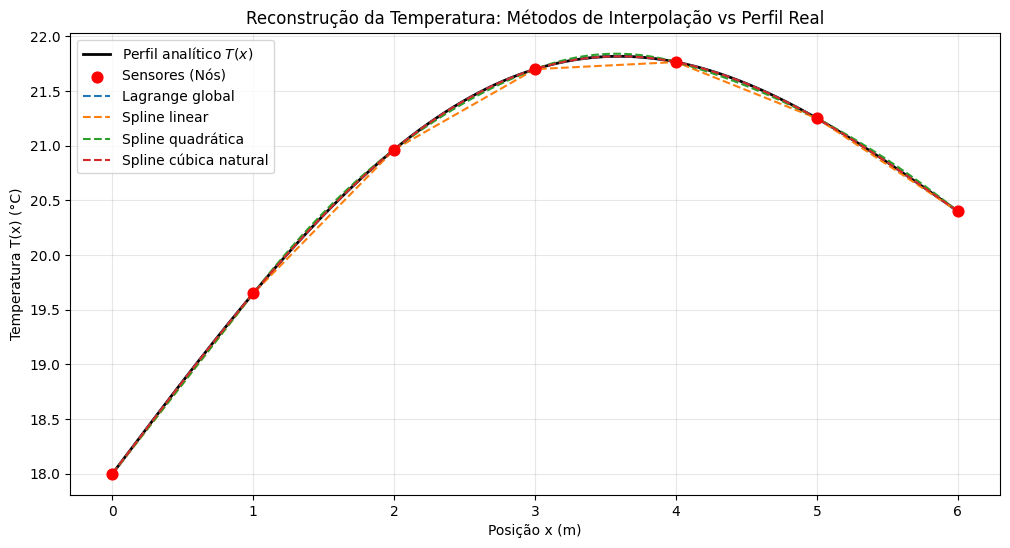

In [4]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Calcular a tabela de métricas na malha fina
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# Sobreponha os quatro métodos à função verdadeira e marque os nós
plt.figure(figsize=(12, 6))
plt.plot(x_fino, T_fino, 'k-', linewidth=2, label='Perfil analítico $T(x)$')
plt.scatter(x_nos_7, y_nos_7, color='red', s=60, zorder=5, label='Sensores (Nós)')

cores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for (nome, metodo), cor in zip(metodos_7.items(), cores):
    plt.plot(x_fino, metodo(x_fino), '--', color=cor, label=nome)

plt.title('Reconstrução da Temperatura: Métodos de Interpolação vs Perfil Real', fontsize=12)
plt.xlabel('Posição x (m)')
plt.ylabel('Temperatura T(x) (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


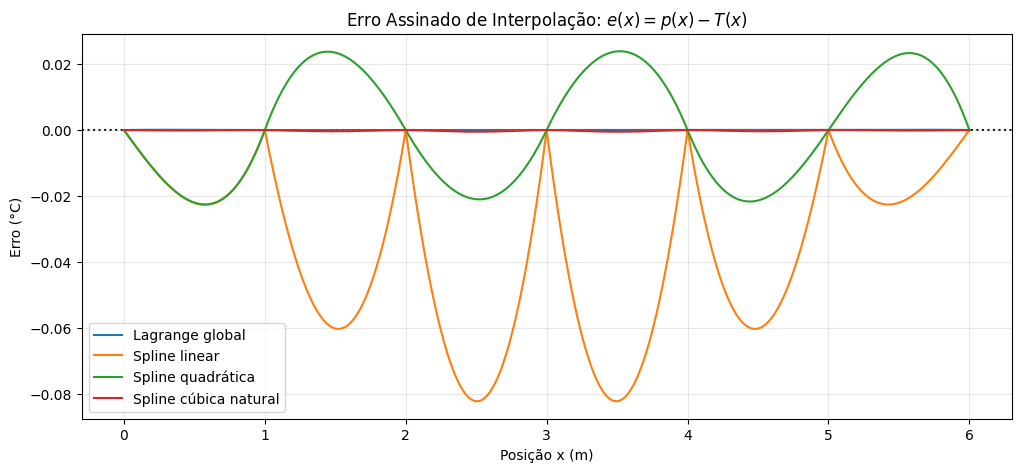

In [5]:
# Gráfico dos erros assinados método a método.
# erro = metodo(x_fino) - T_fino

plt.figure(figsize=(12, 5))

for (nome, metodo), cor in zip(metodos_7.items(), cores):
    erro = metodo(x_fino) - T_fino
    plt.plot(x_fino, erro, color=cor, label=nome)

plt.axhline(0, color='black', linewidth=1.5, linestyle=':', zorder=1)
plt.title('Erro Assinado de Interpolação: $e(x) = p(x) - T(x)$', fontsize=12)
plt.xlabel('Posição x (m)')
plt.ylabel('Erro (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [6]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

resultados = []
Ns = [5, 9, 13, 17]

for N in Ns:
    # Nós equiespaçados
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    lag_eq = BarycentricInterpolator(x_eq, y_eq)
    erro_eq = lag_eq(x_fino) - T_fino
    emax_eq = np.max(np.abs(erro_eq))
    rmse_eq = np.sqrt(np.mean(erro_eq**2))

    # Nós de Chebyshev
    x_cheb = nos_chebyshev_lobatto(x_min, x_max, N)
    y_cheb = temperatura_real(x_cheb)
    lag_cheb = BarycentricInterpolator(x_cheb, y_cheb)
    erro_cheb = lag_cheb(x_fino) - T_fino
    emax_cheb = np.max(np.abs(erro_cheb))
    rmse_cheb = np.sqrt(np.mean(erro_cheb**2))

    resultados.append({
        "N": N,
        "Distribuição": "Equiespaçados",
        "Erro máximo (°C)": emax_eq,
        "RMSE (°C)": rmse_eq
    })
    resultados.append({
        "N": N,
        "Distribuição": "Chebyshev",
        "Erro máximo (°C)": emax_cheb,
        "RMSE (°C)": rmse_cheb
    })

tabela_nos = pd.DataFrame(resultados)
display(tabela_nos)


,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.530257e-03,2.159567e-03
1,5,Chebyshev,2.326599e-03,1.532697e-03
2,9,Equiespaçados,1.043537e-06,3.438146e-07
3,9,Chebyshev,2.167582e-07,1.202332e-07
4,13,Equiespaçados,5.912781e-11,1.545685e-11
5,13,Chebyshev,3.623768e-12,1.932080e-12
6,17,Equiespaçados,1.989520e-12,2.445428e-13
7,17,Chebyshev,1.065814e-14,3.738708e-15


## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

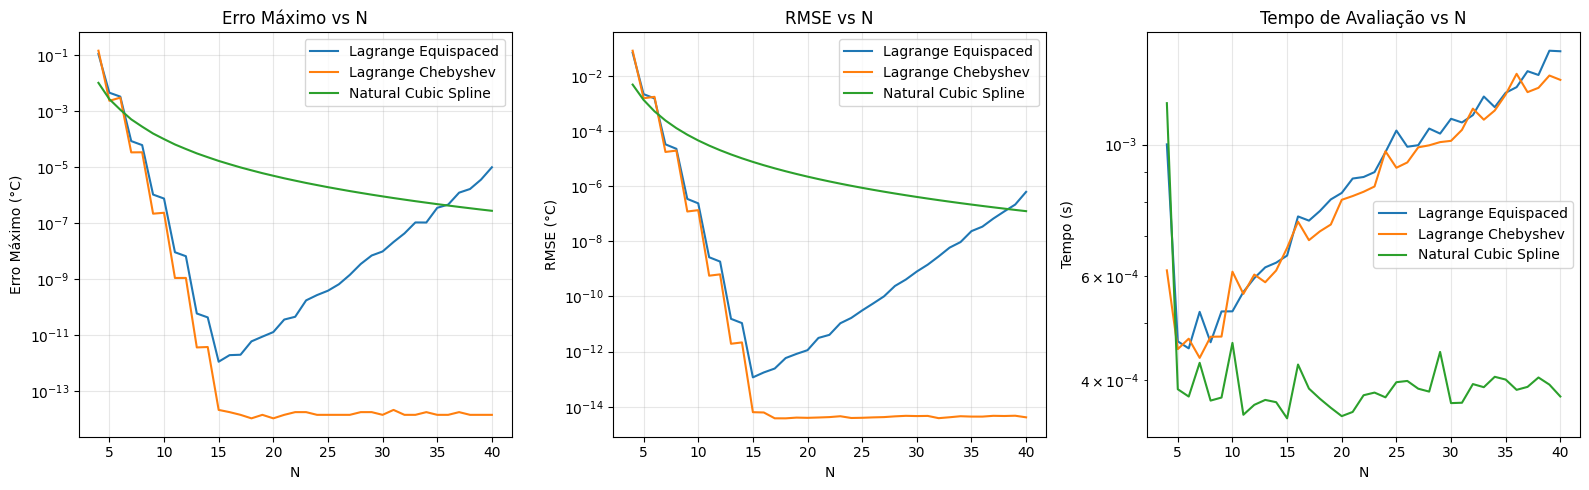

In [7]:
import time

n_values = np.arange(4, 41)

max_err_lag_eq = []
rmse_lag_eq = []
time_lag_eq = []

max_err_lag_cheb = []
rmse_lag_cheb = []
time_lag_cheb = []

max_err_spline = []
rmse_spline = []
time_spline = []

for N_val in n_values:
    # Equispaced nodes
    x_eq_n = np.linspace(x_min, x_max, N_val)
    y_eq_n = temperatura_real(x_eq_n)

    # Chebyshev nodes
    x_cheb_n = nos_chebyshev_lobatto(x_min, x_max, N_val)
    y_cheb_n = temperatura_real(x_cheb_n)

    # 1. Lagrange Equispaced
    t_start = time.perf_counter()
    lag_eq_model = BarycentricInterpolator(x_eq_n, y_eq_n)
    y_pred_eq = lag_eq_model(x_fino)
    t_end = time.perf_counter()

    err_eq = y_pred_eq - T_fino
    max_err_lag_eq.append(np.max(np.abs(err_eq)))
    rmse_lag_eq.append(np.sqrt(np.mean(err_eq**2)))
    time_lag_eq.append(t_end - t_start)

    # 2. Lagrange Chebyshev
    t_start = time.perf_counter()
    lag_cheb_model = BarycentricInterpolator(x_cheb_n, y_cheb_n)
    y_pred_cheb = lag_cheb_model(x_fino)
    t_end = time.perf_counter()

    err_cheb = y_pred_cheb - T_fino
    max_err_lag_cheb.append(np.max(np.abs(err_cheb)))
    rmse_lag_cheb.append(np.sqrt(np.mean(err_cheb**2)))
    time_lag_cheb.append(t_end - t_start)

    # 3. Natural Cubic Spline (Equispaced)
    t_start = time.perf_counter()
    spline_model = CubicSpline(x_eq_n, y_eq_n, bc_type='natural')
    y_pred_spline = spline_model(x_fino)
    t_end = time.perf_counter()

    err_spline = y_pred_spline - T_fino
    max_err_spline.append(np.max(np.abs(err_spline)))
    rmse_spline.append(np.sqrt(np.mean(err_spline**2)))
    time_spline.append(t_end - t_start)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot Max Error
axes[0].plot(n_values, max_err_lag_eq, label='Lagrange Equispaced')
axes[0].plot(n_values, max_err_lag_cheb, label='Lagrange Chebyshev')
axes[0].plot(n_values, max_err_spline, label='Natural Cubic Spline')
axes[0].set_yscale('log')
axes[0].set_title('Erro Máximo vs N')
axes[0].set_xlabel('N')
axes[0].set_ylabel('Erro Máximo (°C)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot RMSE
axes[1].plot(n_values, rmse_lag_eq, label='Lagrange Equispaced')
axes[1].plot(n_values, rmse_lag_cheb, label='Lagrange Chebyshev')
axes[1].plot(n_values, rmse_spline, label='Natural Cubic Spline')
axes[1].set_yscale('log')
axes[1].set_title('RMSE vs N')
axes[1].set_xlabel('N')
axes[1].set_ylabel('RMSE (°C)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot Time
axes[2].plot(n_values, time_lag_eq, label='Lagrange Equispaced')
axes[2].plot(n_values, time_lag_cheb, label='Lagrange Chebyshev')
axes[2].plot(n_values, time_spline, label='Natural Cubic Spline')
axes[2].set_yscale('log')
axes[2].set_title('Tempo de Avaliação vs N')
axes[2].set_xlabel('N')
axes[2].set_ylabel('Tempo (s)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Discussão da Etapa 3

1. **Estabilidade Numérica:** Fica evidente o Fenômeno de Runge para o polinômio de Lagrange com nós equiespaçados. A partir de $N \approx 15$, o erro começa a crescer drasticamente de forma exponencial nas extremidades. Usar nós de Chebyshev estabiliza o método de Lagrange e apresenta convergência espetacular, atingindo a precisão da máquina muito rápido. A Spline Cúbica Natural é inerentemente estável e não sofre oscilações drásticas com o aumento de $N$, porém sua precisão decai apenas de forma polinomial e nunca atinge a precisão extrema do Lagrange com Chebyshev para esse perfil de referência.

2. **Custo Computacional:** A Spline Cúbica possui uma etapa de construção mais complexa (solução de sistema tridiagonal), mas a avaliação por intervalos é barata. O modelo de Lagrange pelo interpolador baricêntrico também é otimizado, sendo muito rápido de construir, com tempos de avaliação competitivos. Em geral, o custo de tempo é tão pequeno neste caso (frações de milissegundos) que não é o fator limitante na escolha.

3. **Há um método sempre superior para todo $N$?** Não.
   - Para $N$ pequeno (por volta de 4 a 6), os erros dos métodos são comparáveis, e frequentemente a Spline se comporta melhor em aplicações práticas.
   - Para $N$ médio e grande, se os dados forem exatos e gerados por uma função contínua e suave (como nosso perfil analítico), o polinômio de Lagrange com nós de Chebyshev é amplamente superior.
   - Se utilizarmos nós equiespaçados obrigatoriamente (limitação de design de sensores, por exemplo) para um grande volume de nós, a Spline Cúbica é a única opção estável, sendo infinitamente superior ao Lagrange que diverge pelo Fenômeno de Runge.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Recomendação Técnica (Etapa 4)

Com base nos experimentos numéricos realizados, a equipe deve seguir as seguintes diretrizes para estimar as temperaturas internas da barra:

1. **Poucos sensores exatos:** Para poucos sensores (ex: $N \le 6$), a **Spline Cúbica Natural** é altamente recomendada. Ela é numericamente robusta e fisicamente condizente com fenômenos suaves de condução de calor. Na Etapa 1, com 7 sensores, ela apresentou um **RMSE** muito baixo (cerca de $0.0002\ ^\circ\mathrm{C}$) e o comportamento global entre nós oscilou minimamente em relação ao real.

2. **Aumento do número de sensores:** Se o número de sensores for muito grande e o espaçamento for forçosamente uniforme (equiespaçado), deve-se manter o uso de **Splines Cúbicas**. O uso de um Polinômio Global de Lagrange para muitos nós equiespaçados é catastrófico devido ao Fenômeno de Runge (oscilações extremas, elevando drasticamente o **Erro Máximo**). No entanto, se a equipe tiver a liberdade de posicionar os sensores nas posições de **Chebyshev**, o polinômio de Lagrange é superior, fazendo o erro despencar próximo à precisão de máquina.

3. **Presença de ruído:** Modelos de interpolação forçam a curva a passar *exatamente* sobre os pontos medidos. Com ruído, isso cria picos e vales irreais. A Spline Cúbica consegue limitar a perturbação localmente, mas a longo prazo (especialmente com sensores ruidosos), a equipe deve abandonar métodos de interpolação exata e utilizar **Ajuste de Curvas por Mínimos Quadrados** para filtrar os erros de medição, pois a regressão não é obrigada a passar por todos os nós.

4. **Cuidados nas extremidades:** É vital **diferenciar interpolação (dentro do domínio $[0, L]$) de extrapolação (fora dele)**. As métricas de **Erro Máximo** e **RMSE** avaliadas aqui valem apenas entre os limites medidos. Nas extremidades, os modelos globais são muito sensíveis. Extrapolar valores de temperatura usando os polinômios ajustados fora do intervalo de sensores resultará em erros absurdos e deve ser evitado a todo custo.

5. **Limitações na prática:** Sem conhecer a "verdade" ($T(x)$ analítico), não podemos calcular o **RMSE** da reconstrução em campo. A principal limitação é que a equipe operará "às cegas" sobre as posições não medidas. A solução prática é utilizar *validação cruzada* (remover a leitura de 1 sensor, ajustar a curva com os restantes e medir o erro no sensor removido) para inferir a confiabilidade das estimativas.